In [1]:
import tensorflow as tf
import numpy as np

import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report

from matplotlib import pyplot as plt
from tqdm import tqdm

from TheModel import build

In [2]:
print("Versiones:")
print(f"- TensorFlow: {tf.__version__}")
print(f"- NumPy: {np.__version__}")
print(f"- Scikit-Learn: {sklearn.__version__}")


Versiones:
- TensorFlow: 2.21.0
- NumPy: 2.5.4
- Scikit-Learn: 1.9.1


## APRENDIZAJE FEDERADO.

El aprendizaje federado consiste en entrenar un modelo localmente con un subconjunto de datos, para después computar un modelo global (idéntico) que será desplegado como un servicio.

Para simular una situación de aprendizaje federado, usaremos la bien-conocida base de datos MNIST para interpretar número escritos a mano, y la dividiremos en cuatro partes (dado que somos cuatro integrantes en el equipo).

### 1. Carga de datos

Cargamos MNIST, normalizamos los píxeles a [0, 1] y añadimos la dimensión de canal.

In [3]:
train, test = tf.keras.datasets.mnist.load_data()

x_train, x_test = np.expand_dims(train[0] / 255.0, -1), np.expand_dims(test[0] / 255.0, -1)
y_train, y_test = train[1], test[1]

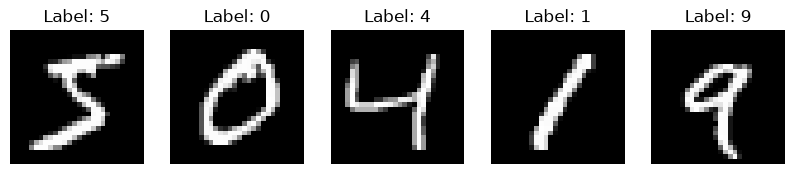

In [4]:
plt.figure(figsize=(10, 5))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

### 2. División de datos

Partimos el conjunto de entrenamiento en cuatro subconjuntos estratificados para simular cinco dispositivos con datos aparte.

In [5]:
skf = StratifiedKFold(n_splits = 4) # cuatro integrantes
folds = skf.split(x_train, y_train)

local_data = [(x_train[tsix], y_train[tsix]) for _, tsix in folds]

for x in local_data:
    print("#"*20)
    print(len(x[0]))
    print(f"Frecuencia de números: { {int(y):list(x[1]).count(y) for y in set(x[1])} }")
    print(f"Primeros ejemplos (labels): {[int(y) for y in list(x[1])[:15]]}")

####################
15000
Frecuencia de números: {0: 1480, 1: 1685, 2: 1489, 3: 1533, 4: 1461, 5: 1356, 6: 1479, 7: 1567, 8: 1462, 9: 1488}
Primeros ejemplos (labels): [5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1]
####################
15000
Frecuencia de números: {0: 1481, 1: 1685, 2: 1490, 3: 1533, 4: 1461, 5: 1355, 6: 1479, 7: 1566, 8: 1463, 9: 1487}
Primeros ejemplos (labels): [7, 7, 0, 7, 7, 7, 3, 3, 7, 0, 0, 3, 7, 3, 7]
####################
15000
Frecuencia de números: {0: 1481, 1: 1686, 2: 1490, 3: 1532, 4: 1460, 5: 1355, 6: 1480, 7: 1566, 8: 1463, 9: 1487}
Primeros ejemplos (labels): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
####################
15000
Frecuencia de números: {0: 1481, 1: 1686, 2: 1489, 3: 1533, 4: 1460, 5: 1355, 6: 1480, 7: 1566, 8: 1463, 9: 1487}
Primeros ejemplos (labels): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 9, 9]


### 3. Entrenamientos locales

Cada uno de estos entrenamientos debe hacerse en computadoras aparte. Cada modelo local se guarda como `lmodel_{i}.keras`.

In [ ]:
def train_and_verify(local_model, local_data, epochs, x_test, y_test, save_name):

    history = local_model.fit(
        local_data[0], 
        local_data[1], 
        epochs=epochs, 
        validation_data=(x_test, y_test)
    )

    y_pred = local_model.predict(x_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    
    with open(f"./reports/{save_name}", 'w', encoding='utf-8') as f:
        output = classification_report(y_test, y_pred_classes)
        f.write(output)

    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.savefig(f"./viz/{save_name}")
    plt.close()

    local_model.save(f"./models/{save_name}.keras")

In [7]:
for x in tqdm(range(len(local_data)), desc="Local folds"):
    local_model = build.build_it()
    train_and_verify(
        local_model, 
        local_data = local_data[x], 
        epochs = 5, 
        x_test = x_test, 
        y_test = y_test, 
        save_name = f"lmodel_{x}"
    )

Local folds:   0%|          | 0/4 [00:00<?, ?it/s]c:\Users\rcorr\anaconda3\envs\tf\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.9035 - loss: 0.3171 - val_accuracy: 0.9710 - val_loss: 0.0952
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9727 - loss: 0.0907 - val_accuracy: 0.9724 - val_loss: 0.0925
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9797 - loss: 0.0620 - val_accuracy: 0.9779 - val_loss: 0.0713
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9856 - loss: 0.0444 - val_accuracy: 0.9809 - val_loss: 0.0624
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.9898 - loss: 0.0296 - val_accuracy: 0.9842 - val_loss: 0.0505
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


Local folds:  25%|██▌       | 1/4 [01:06<03:20, 66.76s/it]c:\Users\rcorr\anaconda3\envs\tf\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.9082 - loss: 0.3126 - val_accuracy: 0.9621 - val_loss: 0.1158
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9724 - loss: 0.0877 - val_accuracy: 0.9755 - val_loss: 0.0794
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9815 - loss: 0.0580 - val_accuracy: 0.9817 - val_loss: 0.0589
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9873 - loss: 0.0396 - val_accuracy: 0.9833 - val_loss: 0.0540
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9897 - loss: 0.0298 - val_accuracy: 0.9841 - val_loss: 0.0514
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


Local folds:  50%|█████     | 2/4 [02:04<02:03, 61.63s/it]c:\Users\rcorr\anaconda3\envs\tf\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.9009 - loss: 0.3222 - val_accuracy: 0.9651 - val_loss: 0.1064
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9710 - loss: 0.0932 - val_accuracy: 0.9753 - val_loss: 0.0768
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9800 - loss: 0.0644 - val_accuracy: 0.9781 - val_loss: 0.0691
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.9848 - loss: 0.0474 - val_accuracy: 0.9755 - val_loss: 0.0754
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.9887 - loss: 0.0348 - val_accuracy: 0.9816 - val_loss: 0.0589
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


Local folds:  75%|███████▌  | 3/4 [03:01<00:59, 59.19s/it]c:\Users\rcorr\anaconda3\envs\tf\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.8999 - loss: 0.3315 - val_accuracy: 0.9634 - val_loss: 0.1187
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.9714 - loss: 0.0924 - val_accuracy: 0.9776 - val_loss: 0.0699
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.9793 - loss: 0.0621 - val_accuracy: 0.9802 - val_loss: 0.0603
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.9886 - loss: 0.0399 - val_accuracy: 0.9787 - val_loss: 0.0642
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.9889 - loss: 0.0319 - val_accuracy: 0.9800 - val_loss: 0.0651
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


Local folds: 100%|██████████| 4/4 [04:04<00:00, 61.17s/it]


### 4. Comparación: modelo entrenado en un solo dispositivo

Como referencia, entrenamos el mismo modelo con todos los datos de entrenamiento en un único dispositivo.

c:\Users\rcorr\anaconda3\envs\tf\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 17ms/step - accuracy: 0.9563 - loss: 0.1428 - val_accuracy: 0.9822 - val_loss: 0.0550
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.9855 - loss: 0.0461 - val_accuracy: 0.9874 - val_loss: 0.0375
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.9897 - loss: 0.0327 - val_accuracy: 0.9897 - val_loss: 0.0320
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9925 - loss: 0.0240 - val_accuracy: 0.9871 - val_loss: 0.0399
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step - accuracy: 0.9947 - loss: 0.0173 - val_accuracy: 0.9921 - val_loss: 0.0262
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       1.00      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      1.00

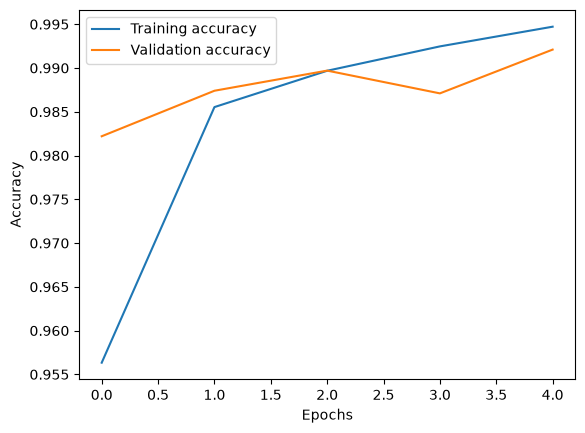

In [8]:
model = build.build_it()

history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
print(classification_report(y_test, y_pred_classes))

plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()